## Cell 1: Setup Environment & Penyimpanan


In [ ]:
!pip install -q google-play-scraper Sastrawi

import os, re, shutil, warnings
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
from google.colab import files

# ---------- KONFIGURASI PENYIMPANAN ----------
DOWNLOAD_FILES = True    # True = otomatis memicu download ke komputer
USE_DRIVE      = False   # True = salin juga ke Google Drive (akan diminta izin)
DRIVE_DIR      = "/content/drive/MyDrive/case_method_bert"

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)

def export_file(path):
    """Salin ke Drive (opsional) dan/atau unduh ke komputer lokal."""
    if USE_DRIVE:
        shutil.copy(path, os.path.join(DRIVE_DIR, os.path.basename(path)))
    if DOWNLOAD_FILES:
        try:
            files.download(path)
        except Exception as e:
            print(f"Download otomatis gagal untuk {path}: {e}")
    print(f"Tersimpan: {path}")

print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "TIDAK TERDETEKSI (aktifkan T4 GPU di Runtime > Change runtime type)")

PyTorch : 2.14.1+cu130
GPU     : Tesla T4


## Cell 2: Pengumpulan Data (Scraping) & Label Baseline


In [3]:
import pandas as pd
from google_play_scraper import reviews, Sort

# ---------- GANTI SESUAI KASUS ANDA ----------
APP_NAME = "MyPertamina"
APP_ID   = "com.dafturn.mypertamina"
N_REVIEWS = 500

# Ambil sedikit lebih banyak (600) supaya setelah ulasan kosong dibuang, tetap tersisa 500
result, _ = reviews(APP_ID, lang="id", country="id", sort=Sort.NEWEST, count=N_REVIEWS + 100)

df = pd.DataFrame(result)[["reviewId", "userName", "content", "score", "at", "thumbsUpCount"]]
df = df.dropna(subset=["content"])
df = df[df["content"].str.strip() != ""]
df = df.sort_values("at", ascending=False).head(N_REVIEWS).reset_index(drop=True)

def map_rating(s):
    if s <= 2: return "negative"
    if s == 3: return "neutral"
    return "positive"

df["label_true"] = df["score"].apply(map_rating)

df.to_csv("dataset_raw.csv", index=False)
print(f"Aplikasi : {APP_NAME} ({APP_ID})")
print(f"Jumlah   : {len(df)} ulasan | periode {df['at'].min():%Y-%m-%d} s.d. {df['at'].max():%Y-%m-%d}")
print("\nDistribusi rating (baseline):")
print(df["label_true"].value_counts().to_string())
display(df[["content", "score", "label_true"]].head())
export_file("dataset_raw.csv")

ModuleNotFoundError: No module named 'google_play_scraper'

## Cell 3: Text Preprocessing (Khusus BERT)


In [ ]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)        # URL
    t = re.sub(r"[^a-z0-9\s.,!?'-]", " ", t)       # emoji sama karakter aneh
    t = re.sub(r"([.,!?])\1+", r"\1", t)           # tanda baca berulang
    t = re.sub(r"\s+", " ", t).strip()             # spasi berlebih
    return t

df = pd.read_csv("dataset_raw.csv")
df["text_clean"] = df["content"].apply(clean_text)

# Buang ulasan yang setelah dibersihkan tidak punya huruf sama sekali (mis. hanya emoji)
before = len(df)
df = df[df["text_clean"].str.contains(r"[a-z]", regex=True)].reset_index(drop=True)
print(f"Ulasan dibuang (kosong setelah dibersihkan): {before - len(df)} | tersisa: {len(df)}")

display(df[["content", "text_clean"]].sample(5, random_state=42))

Ulasan dibuang (kosong setelah dibersihkan): 5 | tersisa: 495


,content,text_clean
456,lancar jaya,lancar jaya
73,"saat chat,telpon dan email costumer servise ti...","saat chat,telpon dan email costumer servise ti..."
310,pokoke mantulll,pokoke mantulll
175,aneh masa mau daftar buat barcode ditolak alas...,aneh masa mau daftar buat barcode ditolak alas...
333,mantap,mantap


## Cell 4: Pemodelan, Inference IndoBERT (GPU)


In [ ]:
import time
from transformers import pipeline, logging as hf_logging
hf_logging.set_verbosity_error()

MODEL_NAME = "mdhugol/indonesia-bert-sentiment-classification"
LABEL_MAP  = {"LABEL_0": "positive", "LABEL_1": "neutral", "LABEL_2": "negative"}

clf = pipeline(
    "text-classification",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=0 if torch.cuda.is_available() else -1,
)

t0 = time.time()
preds = clf(df["text_clean"].tolist(), batch_size=32, truncation=True, max_length=512)
print(f"Inference {len(df)} ulasan selesai dalam {time.time() - t0:.1f} detik")

df["label_bert"] = [LABEL_MAP[p["label"]] for p in preds]
df["bert_conf"]  = [round(p["score"], 4) for p in preds]

df.to_csv("hasil_bert.csv", index=False)
print(df["label_bert"].value_counts().to_string())
display(df[["text_clean", "score", "label_true", "label_bert", "bert_conf"]].head())
export_file("hasil_bert.csv")

config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

... (4 outputs left out)

,text_clean,score,label_true,label_bert,bert_conf
0,aplikasi busuk ga heran apk buatan pemerintah ...,1,negative,negative,0.9980
1,cepat,5,positive,positive,0.9794
2,semakin maju harus lebih baik bbm jangan sampa...,5,positive,negative,0.9835
3,verifikasi data di tolak dengan keterangan fot...,1,negative,negative,0.8625
4,keren,5,positive,positive,0.9972


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tersimpan: hasil_bert.csv


## Cell 5: Evaluasi Model


Accuracy (3 kelas)            : 0.786
Accuracy (tanpa neutral/3*)   : 0.819

              precision    recall  f1-score   support

    negative      0.775     0.833     0.803       186
     neutral      0.133     0.267     0.178        30
    positive      0.962     0.810     0.879       279

    accuracy                          0.786       495
   macro avg      0.623     0.637     0.620       495
weighted avg      0.841     0.786     0.808       495



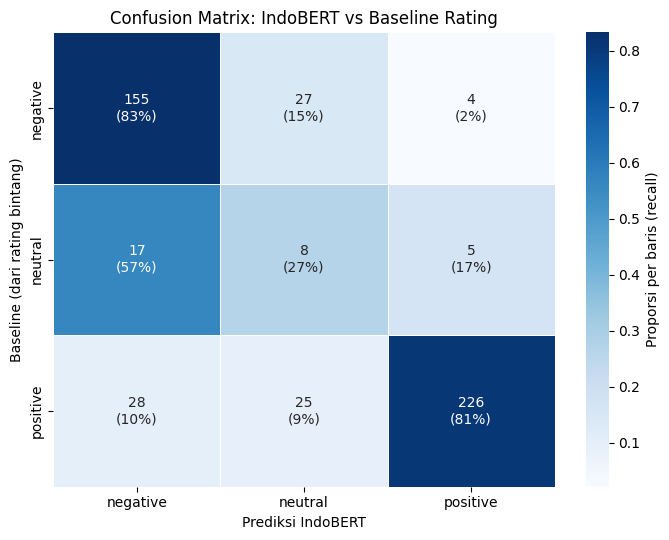

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tersimpan: confusion_matrix.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df_eval = pd.read_csv("hasil_bert.csv")
LABELS = ["negative", "neutral", "positive"]
y_true, y_pred = df_eval["label_true"], df_eval["label_bert"]

print(f"Accuracy (3 kelas)            : {accuracy_score(y_true, y_pred):.3f}")
m = y_true != "neutral"
print(f"Accuracy (tanpa neutral/3*)   : {accuracy_score(y_true[m], y_pred[m]):.3f}\n")
print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=LABELS)
cm_pct = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float),
                   where=cm.sum(axis=1, keepdims=True) != 0)
annot = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0%})" for j in range(3)] for i in range(3)])

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS,
            cbar_kws={"label": "Proporsi per baris (recall)"}, linewidths=.5)
plt.xlabel("Prediksi IndoBERT")
plt.ylabel("Baseline (dari rating bintang)")
plt.title("Confusion Matrix: IndoBERT vs Baseline Rating")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
export_file("confusion_matrix.png")

## Cell 6: Analisis Pola & Faktor Berpengaruh (Inti Case Method)
### 6A. Kasus anomali / diskrepansi


In [ ]:
import textwrap
pd.set_option("display.max_colwidth", None)

d = pd.read_csv("hasil_bert.csv")
hi_but_neg = d[(d["score"] >= 4) & (d["label_bert"] == "negative")]
lo_but_pos = d[(d["score"] <= 2) & (d["label_bert"] == "positive")]

print(f"Rating 4-5 tapi diprediksi negative : {len(hi_but_neg)} ({len(hi_but_neg)/len(d):.1%} dari seluruh data)")
print(f"Rating 1-2 tapi diprediksi positive : {len(lo_but_pos)} ({len(lo_but_pos)/len(d):.1%} dari seluruh data)\n")

anom = pd.concat([
    hi_but_neg.sample(min(6, len(hi_but_neg)), random_state=42),
    lo_but_pos.sample(min(4, len(lo_but_pos)), random_state=42),
])[["content", "score", "label_true", "label_bert", "bert_conf"]].reset_index(drop=True)

for i, r in anom.iterrows():
    print(f"[{i+1}] Rating {r['score']} ({r['label_true']}) -> BERT: {r['label_bert']} (conf {r['bert_conf']:.2f})")
    print(textwrap.fill(str(r["content"]), width=110, initial_indent="    ", subsequent_indent="    "))
    print()

anom.to_csv("contoh_anomali.csv", index=False)
export_file("contoh_anomali.csv")

Rating 4-5 tapi diprediksi negative : 28 (5.7% dari seluruh data)
Rating 1-2 tapi diprediksi positive : 4 (0.8% dari seluruh data)

[1] Rating 5 (positive) -> BERT: negative (conf 1.00)
    aplikasi yg tidak memihak masyarakat sistem bayarnya juga tidak efisien hanya utk mementingkan satu
    individu saja.. dan terkena biaya tambahan utk biaya admin

[2] Rating 4 (positive) -> BERT: negative (conf 1.00)
    aplikasinya sangat lelet, tolong di tingkat kan lagi, tidak enak sm yg antri klw aplikasi lelet saat di
    bukak

[3] Rating 5 (positive) -> BERT: negative (conf 0.94)
    kenapa aplikasinya tidak bisa di buka alias mati sendiri

[4] Rating 5 (positive) -> BERT: negative (conf 1.00)
    buka aplikasi my pertamina lemot

[5] Rating 5 (positive) -> BERT: negative (conf 0.98)
    semakin maju harus lebih baik BBM jangan sampai telat telat kasihan masyarakat

[6] Rating 4 (positive) -> BERT: negative (conf 0.87)
    barcode tudak muncul

[7] Rating 1 (negative) -> BERT: positive (conf

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tersimpan: contoh_anomali.csv


### 6B. Ekstraksi frasa keluhan (bigram) pada ulasan *negative*


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

KEEP = {"tidak", "tak", "bukan", "belum", "jangan", "tanpa", "kurang", "bisa",
        "susah", "sulit", "gak", "ga", "nggak", "gagal", "error"}
EXTRA_STOP = {"aplikasi", "app", "apk", "mohon", "tolong", "banget", "sangat", "sekali",
              "yg", "dgn", "utk", "udah", "sudah", "aja", "nya", "sih", "deh", "dong"}
stop_ind = (set(StopWordRemoverFactory().get_stop_words()) - KEEP) | EXTRA_STOP

neg_texts = d.loc[d["label_bert"] == "negative", "text_clean"]
print(f"Jumlah ulasan negative yang dianalisis: {len(neg_texts)}")

vec = CountVectorizer(ngram_range=(2, 2), stop_words=list(stop_ind), min_df=2)
X = vec.fit_transform(neg_texts)
freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=vec.get_feature_names_out())
top_bigram = freq.sort_values(ascending=False).head(10)
display(top_bigram.rename("frekuensi").to_frame())

Jumlah ulasan negative yang dianalisis: 200


,frekuensi
tidak bisa,11
gak bisa,9
ga bisa,7
mau bayar,6
my pertamina,6
ribet mau,5
mau isi,5
gagal terus,5
pas mau,5
ganti plat,4


### 6C. Dua grafik siap tempel ke slide/laporan


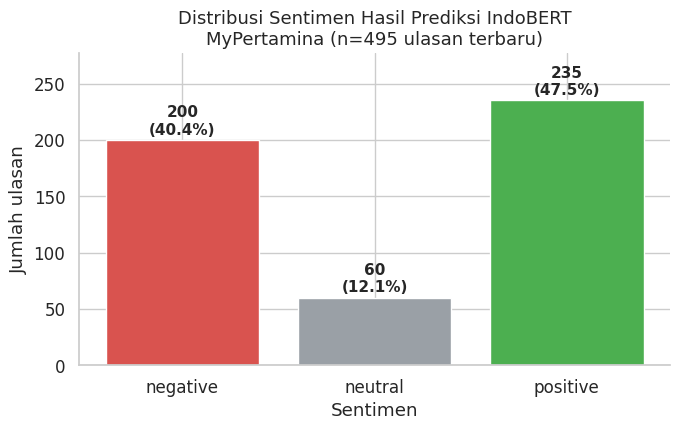

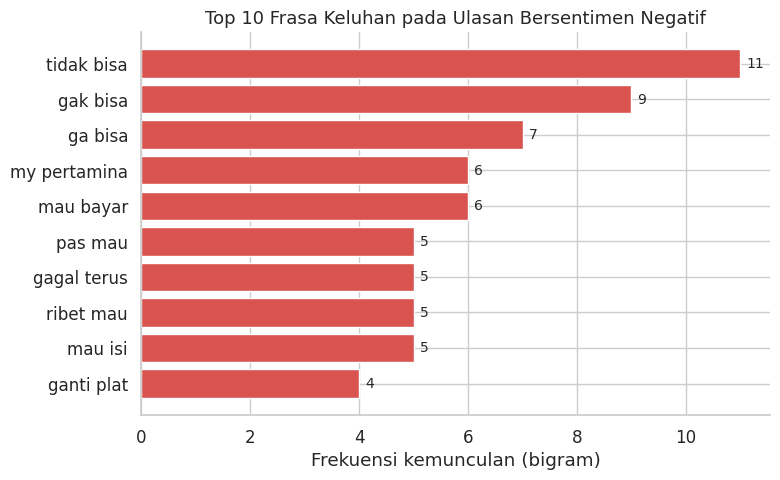

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tersimpan: grafik_distribusi_sentimen.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tersimpan: grafik_top10_frasa_keluhan.png


In [ ]:
sns.set_theme(style="whitegrid", font_scale=1.1)

# ---- Grafik 1: Distribusi Sentimen Prediksi BERT ----
order  = ["negative", "neutral", "positive"]
colors = {"negative": "#D9534F", "neutral": "#9AA0A6", "positive": "#4CAF50"}
cnt = d["label_bert"].value_counts().reindex(order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(cnt.index, cnt.values, color=[colors[k] for k in cnt.index], edgecolor="white")
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v + max(cnt.values) * 0.01,
            f"{v}\n({v / cnt.sum():.1%})", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(cnt.values) * 1.18)
ax.set_title(f"Distribusi Sentimen Hasil Prediksi IndoBERT\n{APP_NAME} (n={cnt.sum()} ulasan terbaru)", fontsize=13)
ax.set_xlabel("Sentimen")
ax.set_ylabel("Jumlah ulasan")
sns.despine()
plt.tight_layout()
plt.savefig("grafik_distribusi_sentimen.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- Grafik 2: Top 10 Frasa Keluhan ----
fig, ax = plt.subplots(figsize=(8, 5))
tb = top_bigram.sort_values()
ax.barh(tb.index, tb.values, color="#D9534F")
for y, v in enumerate(tb.values):
    ax.text(v + max(tb.values) * 0.01, y, str(v), va="center", fontsize=10)
ax.set_title("Top 10 Frasa Keluhan pada Ulasan Bersentimen Negatif", fontsize=13)
ax.set_xlabel("Frekuensi kemunculan (bigram)")
sns.despine()
plt.tight_layout()
plt.savefig("grafik_top10_frasa_keluhan.png", dpi=300, bbox_inches="tight")
plt.show()

export_file("grafik_distribusi_sentimen.png")
export_file("grafik_top10_frasa_keluhan.png")

### Output yang dihasilkan
`dataset_raw.csv`, `hasil_bert.csv`, `confusion_matrix.png`, `contoh_anomali.csv`, `grafik_distribusi_sentimen.png`, `grafik_top10_frasa_keluhan.png`

Langkah berikutnya: tulis analisis dan rekomendasi manajemen berdasarkan angka dan contoh nyata dari output di atas.

### 6D. EMETAAN KATEGORI AKAR MASALAH (RULE-BASED MULTI-LABEL)


In [4]:
# === CELL 6D: PEMETAAN KATEGORI AKAR MASALAH (RULE-BASED MULTI-LABEL) ===
import glob
import pandas as pd

matches = glob.glob("hasil_bert*.csv")
if not matches:
    from google.colab import files
    print("Upload file hasil_bert.csv dari laptopmu:")
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
else:
    filename = matches[0]

print(f"Membaca file: {filename}\n")
d = pd.read_csv(filename)
neg = d.loc[d["label_bert"] == "negative", "text_clean"].fillna("")

themes = {
    "QR/Barcode & Ganti Plat": r"qr|barcode|subsidi|plat|nopol|stnk|kendaraan|mobil|motor|verifikasi|scan|spbu|isi|bbm|bensin|pertalite|solar",
    "Stabilitas & Performa Aplikasi": r"login|masuk|otp|daftar|akun|buka|lemot|lelet|loading|error|eror|mati|keluar|force close|bug|update",
    "Pembayaran & E-Wallet": r"bayar|saldo|admin|ewallet|e-wallet|ovo|gopay|linkaja|qris|transaksi|potong|topup|top up|tf|transfer",
}

flags = pd.DataFrame({k: neg.str.contains(v, regex=True) for k, v in themes.items()})
flags["any_match"] = flags.any(axis=1)
flags["num_matches"] = flags[list(themes.keys())].sum(axis=1)

print(f"Total ulasan negatif (denominator): {len(neg)}\n")
for k in themes:
    c = int(flags[k].sum())
    print(f"- {k:32s}: {c:3d} ulasan ({c/len(neg)*100:.1f}%)")

print(f"\nTercakup minimal 1 kategori       : {int(flags['any_match'].sum())} ulasan ({flags['any_match'].mean()*100:.1f}%)")
print(f"Overlap (>1 kategori sekaligus)   : {int((flags['num_matches'] > 1).sum())} ulasan ({(flags['num_matches'] > 1).mean()*100:.1f}%)")
print(f"Lain-lain / keluhan umum          : {int((~flags['any_match']).sum())} ulasan ({(~flags['any_match']).mean()*100:.1f}%)")

Upload file hasil_bert.csv dari laptopmu:


Saving hasil_bert.csv to hasil_bert.csv
Membaca file: hasil_bert.csv

Total ulasan negatif (denominator): 200

- QR/Barcode & Ganti Plat         :  78 ulasan (39.0%)
- Stabilitas & Performa Aplikasi  :  75 ulasan (37.5%)
- Pembayaran & E-Wallet           :  30 ulasan (15.0%)

Tercakup minimal 1 kategori       : 132 ulasan (66.0%)
Overlap (>1 kategori sekaligus)   : 44 ulasan (22.0%)
Lain-lain / keluhan umum          : 68 ulasan (34.0%)
